# UCI HAR — Experiment Training (Transition Classification)

Cold-starts from the `.npz` files produced by `combined_data_split_medical.ipynb`.
Runs the same architecture and loss sweep used for the North Sea dataset to test
**generalisation** of the models to a different physical domain.

## Analogies to North Sea pipeline

| North Sea | UCI HAR (this notebook) |
|---|---|
| Formation top recall (within ±50 m) | Transition classification accuracy |
| MAE (depth prediction error) | Macro-F1 across 6 activity classes |
| `recall_tops` + `Predicted_well_depth_npd` | `evaluate_medical` |
| 7 classes: None + 6 markers | 7 classes: None + 6 activities |
| Feature subsets of well-log channels | Feature subsets of inertial sensor channels |

## How to run
1. Run `combined_data_split_medical.ipynb` first to generate `har_transition/`.
2. Set `MY_SHARD` (0–3) to this VM's slice of the run plan.
3. Run all cells. Results append to `experiment_log_medical__shard{MY_SHARD}.csv`.
4. Use the **Results viewer** cell to merge shard CSVs after all VMs finish.

In [1]:
import pandas as pd
import os
import socket
import subprocess
import uuid
import gc as _gc
import sys as _sys
from pathlib import Path
import numpy as np
import time
from datetime import datetime
import json as _json

from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

from fastai.learner import *
from fastai.metrics import accuracy
from fastai.callback.tracker import EarlyStoppingCallback, SaveModelCallback
from fastai.losses import CrossEntropyLossFlat, FocalLossFlat, LabelSmoothingCrossEntropyFlat
from IPython.display import clear_output, display

# Make geoxts importable when running from datasets/medical/Classification/
def _repo_root():
    p = Path.cwd().resolve()
    for parent in [p] + list(p.parents):
        if (parent / "setup.py").is_file() and (parent / "geoxts").is_dir():
            return parent
    return None
REPO_ROOT = _repo_root()
if REPO_ROOT is not None and str(REPO_ROOT) not in _sys.path:
    _sys.path.insert(0, str(REPO_ROOT))

from geoxts.benchmark_models import build_model, count_parameters, random_seed, LSTM_2dCNN, LSTM_XCM, XCM_LSTM, LSTM_FCN_2dCNN
from tsai.all import TSDatasets, TSDataLoaders, Categorize, combine_split_data
from tsai.all import FCN, LSTM, XCM, LSTM_FCN

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

MACHINE = socket.gethostname()
try:
    GIT_SHA = subprocess.check_output(
        ["git", "rev-parse", "--short", "HEAD"], stderr=subprocess.DEVNULL
    ).decode().strip()
except Exception:
    GIT_SHA = "unknown"
print(f"Machine: {MACHINE} | git: {GIT_SHA}")

Machine: instance-20260325-155643-dsba-crp-clf | git: unknown


In [2]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

random_seed(0, use_cuda=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)
print("Fully deterministic mode enabled")

Fully deterministic mode enabled


In [3]:
# ── Dataset loader ─────────────────────────────────────────────────────────────
# Mirrors load_dataset() in experiment_training.ipynb (North Sea).
# Always loads from har_transition/ (single variant; no depth/no-depth split).

DATA_DIR = Path("har_transition")


def dataset_available():
    needed = [DATA_DIR / "train.npz", DATA_DIR / "val.npz",
              DATA_DIR / "test.npz",  DATA_DIR / "warm_state.json"]
    return all(p.exists() for p in needed)


def load_dataset():
    """Cold-load all artifacts from har_transition/."""
    if not dataset_available():
        raise FileNotFoundError(
            f"Dataset not found in {DATA_DIR.resolve()}.\n"
            "Run combined_data_split_medical.ipynb first."
        )
    tr = np.load(DATA_DIR / "train.npz")
    vl = np.load(DATA_DIR / "val.npz")
    te = np.load(DATA_DIR / "test.npz")
    with open(DATA_DIR / "warm_state.json") as f:
        ws = _json.load(f)

    return {
        "X_train": tr['X'].astype(np.float32),
        "y_train": tr['y'].astype(np.int64),
        "X_val":   vl['X'].astype(np.float32),
        "y_val":   vl['y'].astype(np.int64),
        "X_test":  te['X'].astype(np.float32),
        "y_test":  te['y'].astype(np.int64),
        "PRED_COLUMN":   ws["PRED_COLUMN"],    # ['None', 'WALKING', ...]
        "MARKERS":       ws["MARKERS"],         # ['WALKING', ...] (classes 1-6)
        "FEATURES_GEOX": ws["FEATURES_GEOX"],  # 9 channel names
        "N_CLASSES":     ws["N_CLASSES"],       # 7
        "WINDOW_LEN":    ws["WINDOW_LEN"],      # 128
    }


status = "OK" if dataset_available() else "MISSING — run combined_data_split_medical.ipynb first"
print(f"har_transition/: {status}")

har_transition/: OK


In [4]:
# ── Evaluation function ────────────────────────────────────────────────────────
# Replaces recall_tops + Predicted_well_depth_npd from the North Sea pipeline.
# Primary metric: transition_recall (accuracy on transition windows, label > 0).
# Direct analogue to North Sea recall_tops: "of the N true transitions,
# how many does the model correctly identify and classify?"

def evaluate_medical(learn, X_test, y_test, pred_column, batch_size=64):
    """Evaluate a trained model on the test set.

    Returns a dict with:
      transition_recall    — accuracy on true-transition windows (label > 0)
      transition_precision — of predicted transitions, fraction that are real
      transition_f1        — harmonic mean of above two
      f1_transition_only   — macro-F1 on classes 1-6, evaluated on true-transition windows
      f1_macro             — macro-F1 across all 7 classes
      median_error         — median |pred_class − true_class| on true-transition windows
                             Analogue of North Sea median absolute depth error (MAE)
      max_class_error      — max |pred_class − true_class| on true-transition windows
                             Analogue of North Sea max_error
      per_class_f1         — list of per-class F1 scores (all 7 classes)
    """
    device = next(learn.model.parameters()).device
    X_t = torch.tensor(X_test, dtype=torch.float32)
    y_t = torch.tensor(y_test, dtype=torch.long)
    test_dl = DataLoader(
        TensorDataset(X_t, y_t), batch_size=batch_size, shuffle=False, num_workers=0
    )
    learn.model.eval()
    all_preds, all_trues = [], []
    with torch.no_grad():
        for xb, yb in test_dl:
            logits = learn.model(xb.to(device))
            all_preds.extend(logits.argmax(dim=-1).cpu().numpy())
            all_trues.extend(yb.numpy())

    all_preds = np.array(all_preds)
    all_trues = np.array(all_trues)

    true_trans_mask = all_trues > 0
    pred_trans_mask = all_preds > 0

    # Recall: of true transition windows, fraction correctly classified
    if true_trans_mask.sum() > 0:
        t_recall = float((all_preds[true_trans_mask] == all_trues[true_trans_mask]).mean())
    else:
        t_recall = float('nan')

    # Precision: of windows predicted as transitions, fraction that actually are
    if pred_trans_mask.sum() > 0:
        t_precision = float((all_trues[pred_trans_mask] > 0).mean())
    else:
        t_precision = float('nan')

    # Transition F1
    if not (np.isnan(t_recall) or np.isnan(t_precision)) and (t_recall + t_precision) > 0:
        t_f1 = 2 * t_precision * t_recall / (t_precision + t_recall)
    else:
        t_f1 = float('nan')

    # Macro-F1 on transition classes only — excludes None entirely
    n_classes = len(pred_column)
    if true_trans_mask.sum() > 0:
        f1_trans_only = float(f1_score(
            all_trues[true_trans_mask], all_preds[true_trans_mask],
            labels=list(range(1, n_classes)), average='macro', zero_division=0,
        ))
    else:
        f1_trans_only = float('nan')

    f1_mac  = float(f1_score(all_trues, all_preds, average='macro', zero_division=0))
    per_cls = f1_score(all_trues, all_preds, average=None, zero_division=0)

    # Median Absolute Class Error (MACE) and max class error on true-transition windows.
    # Analogue of North Sea MAE (median absolute depth error) and max_error.
    if true_trans_mask.sum() > 0:
        abs_errors = np.abs(all_preds[true_trans_mask].astype(int) -
                            all_trues[true_trans_mask].astype(int))
        median_error    = float(np.median(abs_errors))
        max_class_error = float(np.max(abs_errors))
    else:
        median_error    = float('nan')
        max_class_error = float('nan')

    return {
        "transition_recall":    t_recall,
        "transition_precision": t_precision,
        "transition_f1":        t_f1,
        "f1_transition_only":   f1_trans_only,
        "f1_macro":             f1_mac,
        "median_error":         median_error,
        "max_class_error":      max_class_error,
        "per_class_f1":         per_cls.tolist(),
        "all_preds":            all_preds,
        "all_trues":            all_trues,
    }

In [5]:
# ── Shard configuration ────────────────────────────────────────────────────────
MY_SHARD = 0   # set to 0, 1, 2, or 3 on each VM
N_SHARDS = 1

# ── Feature subset registry ───────────────────────────────────────────────────
# Channels: body_acc_x/y/z (0-2), body_gyro_x/y/z (3-5), total_acc_x/y/z (6-8)
FEATURE_SUBSETS_BY_NAME = {
    "all_channels":     ["body_acc_x", "body_acc_y", "body_acc_z",
                         "body_gyro_x", "body_gyro_y", "body_gyro_z",
                         "total_acc_x", "total_acc_y", "total_acc_z"],
    "body_acc_only":    ["body_acc_x", "body_acc_y", "body_acc_z"],
    "body_gyro_only":   ["body_gyro_x", "body_gyro_y", "body_gyro_z"],
    "total_acc_only":   ["total_acc_x", "total_acc_y", "total_acc_z"],
    "body_only":        ["body_acc_x", "body_acc_y", "body_acc_z",
                         "body_gyro_x", "body_gyro_y", "body_gyro_z"],
    "acc_only":         ["body_acc_x", "body_acc_y", "body_acc_z",
                         "total_acc_x", "total_acc_y", "total_acc_z"],
}

def resolve_subset(subset_name, features_geox):
    """Resolve named subset to (channel_indices, channel_names)."""
    names   = FEATURE_SUBSETS_BY_NAME[subset_name]
    missing = [n for n in names if n not in features_geox]
    if missing:
        raise ValueError(f"Subset {subset_name!r} references unknown channels: {missing}")
    indices = [features_geox.index(n) for n in names]
    return indices, names

# ── Architecture registry ─────────────────────────────────────────────────────
# Same architectures as North Sea to enable direct comparison.
ARCH_REGISTRY = {
    "LSTM_2dCNN_default":    (LSTM_2dCNN,      {}),
    "LSTM_XCM_default":      (LSTM_XCM,        {}),
    "LSTM_FCN_default":      (LSTM_FCN,        {}),
    "XCM_LSTM_default":      (XCM_LSTM,        {}),
    "LSTM_FCN_2dCNN_default":(LSTM_FCN_2dCNN,  {}),
}

# ── Arch-loss pairs ───────────────────────────────────────────────────────────
ARCH_LOSS_PAIRS = [
    ("LSTM_2dCNN_default",     "cwl"),
    ("LSTM_FCN_default",       "cwl"),
    ("LSTM_XCM_default",       "cwl"),
    ("LSTM_XCM_default",       "focal"),   # keep as comparison
    ("XCM_LSTM_default",       "cwl"),
    ("LSTM_FCN_2dCNN_default", "cwl"),
]

# ── Common training recipe ────────────────────────────────────────────────────
# Comparison with North Sea experiment_training.ipynb (cell exp-config):
#
#   Parameter              North Sea       Medical         Match?
#   ─────────────────────────────────────────────────────────────────────────
#   fixed_lr               1e-3            1e-3            ✓
#   monitor                "valid_loss"    "valid_loss"    ✓
#   early_stop_patience    6               6               ✓
#   early_stop_min_delta   0.0             0.0             ✓
#   n_epochs               25              25              ✓
#   batch_size             25              25              ✓
#   loss_type              label_smooth    cwl             ✗ intentional —
#                                                            None class dominates
#                                                            medical dataset;
#                                                            cwl is required to
#                                                            learn rare transitions
COMMON_RECIPE = {
    "fixed_lr":             1e-3,
    "monitor":              "valid_loss",
    "early_stop_patience":  6,
    "early_stop_min_delta": 0.0,
    "n_epochs":             25,
    "batch_size":           25,
}

LR_VARIANTS   = [False, True]   # False = fixed lr, True = lr_find
SUBSETS_TO_RUN = list(FEATURE_SUBSETS_BY_NAME.keys())

# ── Run plan ──────────────────────────────────────────────────────────────────
def build_run_plan():
    plan = []
    for subset_name in SUBSETS_TO_RUN:
        for arch_label, loss_type in ARCH_LOSS_PAIRS:
            for use_lr_find in LR_VARIANTS:
                lr_tag = "lr_find" if use_lr_find else "lr_fixed"
                plan.append({
                    "subset_name":  subset_name,
                    "arch_label":   arch_label,
                    "loss_type":    loss_type,
                    "use_lr_find":  use_lr_find,
                    "run_name":     f"{arch_label}__{loss_type}__{subset_name}__{lr_tag}",
                })
    return plan

RUN_PLAN    = build_run_plan()
MY_RUN_PLAN = RUN_PLAN[MY_SHARD::N_SHARDS]

print(f"Global RUN_PLAN size: {len(RUN_PLAN)} runs")
print(f"This shard ({MY_SHARD}/{N_SHARDS}): {len(MY_RUN_PLAN)} runs")
print(f"\nFirst 5 runs in this shard:")
for i, c in enumerate(MY_RUN_PLAN[:5]):
    print(f"  [{i}] {c['run_name']}")

Global RUN_PLAN size: 72 runs
This shard (0/1): 72 runs

First 5 runs in this shard:
  [0] LSTM_2dCNN_default__cwl__all_channels__lr_fixed
  [1] LSTM_2dCNN_default__cwl__all_channels__lr_find
  [2] LSTM_FCN_default__cwl__all_channels__lr_fixed
  [3] LSTM_FCN_default__cwl__all_channels__lr_find
  [4] LSTM_XCM_default__cwl__all_channels__lr_fixed


In [6]:
# ── Class weight helpers ───────────────────────────────────────────────────────
ENS_BETA = 0.999

def _weight_tensor(classes, weights):
    w = np.zeros(int(classes.max()) + 1, dtype=np.float32)
    for c, wt in zip(classes, weights):
        w[int(c)] = wt
    return torch.tensor(w, dtype=torch.float32)

def compute_class_weights(y):
    cl, ct = np.unique(y, return_counts=True)
    return _weight_tensor(cl, len(y) / (len(cl) * ct))

def compute_ens_weights(y):
    cl, ct = np.unique(y, return_counts=True)
    ens = (1 - ENS_BETA) / (1 - ENS_BETA ** ct)
    ens = ens / ens.min()
    return _weight_tensor(cl, ens)

def compute_sqrt_weights(y):
    cl, ct = np.unique(y, return_counts=True)
    w = np.sqrt(len(y) / (len(cl) * ct))
    w = w / w.min()
    return _weight_tensor(cl, w)


# ── Loss builder ──────────────────────────────────────────────────────────────
def build_loss(loss_type, cwl, ens, sqrt, device):
    if loss_type == "ce":             return CrossEntropyLossFlat()
    elif loss_type == "cwl":          return CrossEntropyLossFlat(weight=cwl.to(device))
    elif loss_type == "cwl_sqrt":     return CrossEntropyLossFlat(weight=sqrt.to(device))
    elif loss_type == "ens":          return CrossEntropyLossFlat(weight=ens.to(device))
    elif loss_type == "focal":        return FocalLossFlat(gamma=2.0)
    elif loss_type == "focal_cwl":    return FocalLossFlat(gamma=2.0, weight=cwl.to(device))
    elif loss_type == "focal_ens":    return FocalLossFlat(gamma=2.0, weight=ens.to(device))
    elif loss_type == "label_smooth": return LabelSmoothingCrossEntropyFlat(eps=0.1)
    else: raise ValueError(f"Unknown loss_type={loss_type!r}")


# ── Dataloader builder ────────────────────────────────────────────────────────
def build_dataloader(ds, subset_idx, batch_size):
    """Slice channels and build tsai TSDataLoaders."""
    X_tr = ds["X_train"][:, subset_idx, :]
    X_vl = ds["X_val"][  :, subset_idx, :]
    X, y, splits = combine_split_data([X_tr, X_vl], [ds["y_train"], ds["y_val"]])
    tfms  = [None, [Categorize()]]
    dsets = TSDatasets(X, y, tfms=tfms, splits=splits, inplace=True)
    dls   = TSDataLoaders.from_dsets(
        dsets.train, dsets.valid, bs=batch_size, batch_tfms=[], num_workers=0
    )
    return dls, dls.valid, X_tr.shape

print("Helpers defined.")

Helpers defined.


In [7]:
# ── Training & evaluation loop ─────────────────────────────────────────────────
LOG_PATH  = Path(f"experiment_log_medical__shard{MY_SHARD}.csv")
MODEL_DIR = Path("models_medical")
MODEL_DIR.mkdir(exist_ok=True)

# Load dataset once (cached)
ds = load_dataset()
weights = {
    "cwl":  compute_class_weights(ds["y_train"]),
    "ens":  compute_ens_weights(ds["y_train"]),
    "sqrt": compute_sqrt_weights(ds["y_train"]),
}
print(f"Dataset loaded. Train={ds['X_train'].shape}  Val={ds['X_val'].shape}  Test={ds['X_test'].shape}")
print(f"Classes: {ds['PRED_COLUMN']}")

result_recall = pd.DataFrame(columns=[
    'run_name', 'arch', 'loss', 'subset', 'lr_strategy',
    'transition_recall', 'f1_macro', 'median_error', 'max_class_error', 'eval_time'
])
results = pd.DataFrame(columns=[
    'run_name', 'arch', 'loss', 'subset', 'lr_strategy',
    'train_loss', 'valid_loss', 'accuracy', 'train_time'
])

for combo_idx, combo in enumerate(MY_RUN_PLAN):
    subset_name = combo["subset_name"]
    arch_label  = combo["arch_label"]
    loss_type   = combo["loss_type"]
    use_lr_find = combo["use_lr_find"]
    run_name    = combo["run_name"]
    lr_tag      = "lr_find" if use_lr_find else "lr_fixed"

    print(f"\n[{combo_idx+1}/{len(MY_RUN_PLAN)}] {run_name}")

    random_seed(0, use_cuda=True)

    try:
        subset_idx, subset_names = resolve_subset(subset_name, ds["FEATURES_GEOX"])
    except ValueError as e:
        print(f"  SKIP: {e}")
        continue

    arch_class, arch_kwargs = ARCH_REGISTRY[arch_label]
    R = COMMON_RECIPE

    dls, valid_dl, train_shape = build_dataloader(ds, subset_idx, R["batch_size"])
    print(f"  shape={train_shape}, loss={loss_type}, lr={lr_tag}")

    model     = build_model(arch_class, dls=dls, **arch_kwargs)
    device    = next(model.parameters()).device
    loss_func = build_loss(loss_type, weights["cwl"], weights["ens"], weights["sqrt"], device)
    learn     = Learner(dls, model, loss_func=loss_func, metrics=accuracy)

    if use_lr_find:
        try:
            lr_res = learn.lr_find(show_plot=False)
            lr = lr_res.valley if hasattr(lr_res, 'valley') else float(lr_res)
        except Exception:
            lr = R["fixed_lr"]
    else:
        lr = R["fixed_lr"]

    cbs = [
        SaveModelCallback(monitor=R["monitor"]),
        EarlyStoppingCallback(
            monitor='valid_loss',
            min_delta=R["early_stop_min_delta"],
            patience=R["early_stop_patience"],
        ),
    ]
    t0 = time.time()
    learn.fit_one_cycle(R["n_epochs"], lr, cbs=cbs)
    train_elapsed = time.time() - t0
    vals       = learn.recorder.values[-1]
    best_epoch = len(learn.recorder.values)

    model_path = MODEL_DIR / f"{run_name}.pth"
    torch.save(learn.model.state_dict(), model_path)

    # ── Evaluate on test set ──────────────────────────────────────────────────
    X_te_sub = ds["X_test"][:, subset_idx, :]
    eval_t0  = time.time()
    metrics  = evaluate_medical(learn, X_te_sub, ds["y_test"], ds["PRED_COLUMN"])
    eval_elapsed = time.time() - eval_t0

    # ── Update in-memory leaderboard ──────────────────────────────────────────
    result_recall.loc[combo_idx] = [
        run_name, arch_label, loss_type, subset_name, lr_tag,
        metrics["transition_recall"], metrics["f1_macro"],
        metrics["median_error"], metrics["max_class_error"], int(eval_elapsed),
    ]
    results.loc[combo_idx] = [
        run_name, arch_label, loss_type, subset_name, lr_tag,
        vals[0], vals[1], vals[2], int(train_elapsed),
    ]
    # Primary sort: highest transition_recall; secondary: lowest median_error
    result_recall.sort_values(
        ['transition_recall', 'median_error'], ascending=[False, True],
        kind='stable', ignore_index=True, inplace=True
    )
    results.sort_values('accuracy', ascending=False, kind='stable',
                        ignore_index=True, inplace=True)

    # ── Append to persistent CSV log ──────────────────────────────────────────
    log_row = {
        "run_id":             str(uuid.uuid4()),
        "run_name":           run_name,
        "timestamp":          datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "machine":            MACHINE,
        "git_sha":            GIT_SHA,
        "shard":              MY_SHARD,
        "n_shards":           N_SHARDS,
        "subset_name":        subset_name,
        "feature_names":      ",".join(subset_names),
        "n_channels":         len(subset_idx),
        "arch_label":         arch_label,
        "arch_class":         arch_class.__name__,
        "arch_kwargs":        str(arch_kwargs),
        "loss_type":          loss_type,
        "use_lr_find":        use_lr_find,
        "lr":                 float(lr),
        "monitor":            R["monitor"],
        "patience":           R["early_stop_patience"],
        "min_delta":          R["early_stop_min_delta"],
        "n_epochs":           R["n_epochs"],
        "batch_size":         R["batch_size"],
        "best_epoch":         best_epoch,
        "total_params":       int(count_parameters(model)),
        "train_loss":         float(vals[0]),
        "valid_loss":         float(vals[1]),
        "val_accuracy":       float(vals[2]),
        "f1_macro":           metrics["f1_macro"],
        "transition_recall":  metrics["transition_recall"],
        "median_error":       metrics["median_error"],
        "max_class_error":    metrics["max_class_error"],
        "per_class_f1":       str(metrics["per_class_f1"]),
        "train_time_s":       int(train_elapsed),
        "eval_time_s":        int(eval_elapsed),
        "model_path":         str(model_path),
    }
    log_df = pd.DataFrame([log_row])
    if LOG_PATH.exists():
        log_df.to_csv(LOG_PATH, mode="a", header=False, index=False)
    else:
        log_df.to_csv(LOG_PATH, mode="w", header=True, index=False)

    # ── GPU cleanup ───────────────────────────────────────────────────────────
    learn.model.cpu()
    del learn, model, loss_func
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
    _gc.collect(); _gc.collect()
    try:
        import ctypes
        ctypes.CDLL('libc.so.6').malloc_trim(0)
    except Exception:
        pass

    clear_output(wait=True)
    print(f"Completed {combo_idx+1}/{len(MY_RUN_PLAN)}")
    display(result_recall)
    display(results)

print(f"\nDone. Logged {len(MY_RUN_PLAN)} runs to {LOG_PATH.resolve()}")

Completed 72/72


,run_name,arch,loss,subset,lr_strategy,transition_recall,f1_macro,median_error,max_class_error,eval_time
0,LSTM_FCN_2dCNN_default__cwl__all_channels__lr_fixed,LSTM_FCN_2dCNN_default,cwl,all_channels,lr_fixed,0.909910,0.654350,0.0,5.0,0
1,LSTM_FCN_default__cwl__all_channels__lr_fixed,LSTM_FCN_default,cwl,all_channels,lr_fixed,0.891892,0.710787,0.0,6.0,0
2,LSTM_FCN_default__cwl__body_only__lr_find,LSTM_FCN_default,cwl,body_only,lr_find,0.891892,0.662972,0.0,5.0,0
3,LSTM_FCN_2dCNN_default__cwl__all_channels__lr_find,LSTM_FCN_2dCNN_default,cwl,all_channels,lr_find,0.882883,0.652830,0.0,6.0,0
4,LSTM_FCN_default__cwl__body_only__lr_fixed,LSTM_FCN_default,cwl,body_only,lr_fixed,0.882883,0.686509,0.0,6.0,0
...,...,...,...,...,...,...,...,...,...,...
67,LSTM_XCM_default__focal__acc_only__lr_find,LSTM_XCM_default,focal,acc_only,lr_find,0.333333,0.466460,1.0,6.0,0
68,LSTM_XCM_default__focal__body_acc_only__lr_fixed,LSTM_XCM_default,focal,body_acc_only,lr_fixed,0.324324,0.427378,1.0,6.0,0
69,LSTM_XCM_default__focal__total_acc_only__lr_fixed,LSTM_XCM_default,focal,total_acc_only,lr_fixed,0.261261,0.364105,2.0,6.0,0
70,LSTM_XCM_default__focal__body_gyro_only__lr_fixed,LSTM_XCM_default,focal,body_gyro_only,lr_fixed,0.243243,0.354396,2.0,6.0,0


,run_name,arch,loss,subset,lr_strategy,train_loss,valid_loss,accuracy,train_time
0,XCM_LSTM_default__cwl__body_only__lr_fixed,XCM_LSTM_default,cwl,body_only,lr_fixed,0.290719,0.665620,0.773913,51
1,XCM_LSTM_default__cwl__body_only__lr_find,XCM_LSTM_default,cwl,body_only,lr_find,0.285651,0.707550,0.765217,64
2,LSTM_XCM_default__focal__all_channels__lr_fixed,LSTM_XCM_default,focal,all_channels,lr_fixed,0.098438,0.474241,0.756522,10
3,XCM_LSTM_default__cwl__all_channels__lr_find,XCM_LSTM_default,cwl,all_channels,lr_find,0.226127,0.341862,0.756522,21
4,LSTM_XCM_default__focal__all_channels__lr_find,LSTM_XCM_default,focal,all_channels,lr_find,0.047812,0.383178,0.747826,16
...,...,...,...,...,...,...,...,...,...
67,LSTM_XCM_default__cwl__total_acc_only__lr_find,LSTM_XCM_default,cwl,total_acc_only,lr_find,0.637703,1.014441,0.339130,25
68,LSTM_2dCNN_default__cwl__acc_only__lr_find,LSTM_2dCNN_default,cwl,acc_only,lr_find,0.615165,1.434896,0.304348,14
69,LSTM_2dCNN_default__cwl__acc_only__lr_fixed,LSTM_2dCNN_default,cwl,acc_only,lr_fixed,0.686261,1.388898,0.269565,12
70,LSTM_2dCNN_default__cwl__total_acc_only__lr_fixed,LSTM_2dCNN_default,cwl,total_acc_only,lr_fixed,0.852016,1.233534,0.260870,17



Done. Logged 72 runs to /home/jupyter/experiment_log_medical__shard0.csv


## Results viewer

Concatenates every `experiment_log_medical__shard*.csv` in the working directory.
**Primary ranking: `transition_recall`** (analogue of North Sea `recall_tops`), then `f1_macro`.

In [8]:
shard_files = sorted(Path(".").glob("experiment_log_medical__shard*.csv"))
if not shard_files:
    print("No experiment_log_medical__shard*.csv files found. Run the training loop first.")
else:
    print(f"Found {len(shard_files)} shard files: {[p.name for p in shard_files]}")
    log_all = pd.concat([pd.read_csv(p) for p in shard_files], ignore_index=True)
    print(f"Total rows: {len(log_all)}")

    display_cols = ["run_name", "subset_name", "arch_label", "loss_type",
                    "use_lr_find", "transition_recall", "f1_macro",
                    "median_error", "max_class_error", "machine", "shard"]
    display_cols = [c for c in display_cols if c in log_all.columns]

    print("\nTop 20 by transition_recall (then lowest median_error):")
    display(
        log_all.sort_values(["transition_recall", "median_error"], ascending=[False, True])
               .head(20)[display_cols]
    )

    print("\nTop 20 by f1_macro:")
    display(
        log_all.sort_values("f1_macro", ascending=False)
               .head(20)[display_cols]
    )

    print("\nBest run per arch-loss pair (by transition_recall):")
    if "arch_label" in log_all.columns and "loss_type" in log_all.columns:
        best_per_pair = (
            log_all.sort_values(["transition_recall", "median_error"], ascending=[False, True])
                   .groupby(["arch_label", "loss_type"]).first().reset_index()
        )
        display(best_per_pair[display_cols] if all(
            c in best_per_pair.columns for c in display_cols
        ) else best_per_pair)

Found 1 shard files: ['experiment_log_medical__shard0.csv']
Total rows: 72

Top 20 by transition_recall (then lowest median_error):


,run_name,subset_name,arch_label,loss_type,use_lr_find,transition_recall,f1_macro,median_error,max_class_error,machine,shard
10,LSTM_FCN_2dCNN_default__cwl__all_channels__lr_fixed,all_channels,LSTM_FCN_2dCNN_default,cwl,False,0.909910,0.654350,0.0,5.0,instance-20260325-155643-dsba-crp-clf,0
2,LSTM_FCN_default__cwl__all_channels__lr_fixed,all_channels,LSTM_FCN_default,cwl,False,0.891892,0.710787,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
51,LSTM_FCN_default__cwl__body_only__lr_find,body_only,LSTM_FCN_default,cwl,True,0.891892,0.662972,0.0,5.0,instance-20260325-155643-dsba-crp-clf,0
11,LSTM_FCN_2dCNN_default__cwl__all_channels__lr_find,all_channels,LSTM_FCN_2dCNN_default,cwl,True,0.882883,0.652830,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
50,LSTM_FCN_default__cwl__body_only__lr_fixed,body_only,LSTM_FCN_default,cwl,False,0.882883,0.686509,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
63,LSTM_FCN_default__cwl__acc_only__lr_find,acc_only,LSTM_FCN_default,cwl,True,0.882883,0.483279,0.0,5.0,instance-20260325-155643-dsba-crp-clf,0
59,LSTM_FCN_2dCNN_default__cwl__body_only__lr_find,body_only,LSTM_FCN_2dCNN_default,cwl,True,0.873874,0.677653,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
46,LSTM_FCN_2dCNN_default__cwl__total_acc_only__lr_fixed,total_acc_only,LSTM_FCN_2dCNN_default,cwl,False,0.864865,0.461995,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
71,LSTM_FCN_2dCNN_default__cwl__acc_only__lr_find,acc_only,LSTM_FCN_2dCNN_default,cwl,True,0.864865,0.532383,0.0,5.0,instance-20260325-155643-dsba-crp-clf,0
3,LSTM_FCN_default__cwl__all_channels__lr_find,all_channels,LSTM_FCN_default,cwl,True,0.855856,0.667868,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0



Top 20 by f1_macro:


,run_name,subset_name,arch_label,loss_type,use_lr_find,transition_recall,f1_macro,median_error,max_class_error,machine,shard
57,XCM_LSTM_default__cwl__body_only__lr_find,body_only,XCM_LSTM_default,cwl,True,0.801802,0.736744,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
9,XCM_LSTM_default__cwl__all_channels__lr_find,all_channels,XCM_LSTM_default,cwl,True,0.819820,0.726903,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
8,XCM_LSTM_default__cwl__all_channels__lr_fixed,all_channels,XCM_LSTM_default,cwl,False,0.837838,0.721868,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
2,LSTM_FCN_default__cwl__all_channels__lr_fixed,all_channels,LSTM_FCN_default,cwl,False,0.891892,0.710787,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
58,LSTM_FCN_2dCNN_default__cwl__body_only__lr_fixed,body_only,LSTM_FCN_2dCNN_default,cwl,False,0.855856,0.692995,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
50,LSTM_FCN_default__cwl__body_only__lr_fixed,body_only,LSTM_FCN_default,cwl,False,0.882883,0.686509,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
59,LSTM_FCN_2dCNN_default__cwl__body_only__lr_find,body_only,LSTM_FCN_2dCNN_default,cwl,True,0.873874,0.677653,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
3,LSTM_FCN_default__cwl__all_channels__lr_find,all_channels,LSTM_FCN_default,cwl,True,0.855856,0.667868,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
51,LSTM_FCN_default__cwl__body_only__lr_find,body_only,LSTM_FCN_default,cwl,True,0.891892,0.662972,0.0,5.0,instance-20260325-155643-dsba-crp-clf,0
56,XCM_LSTM_default__cwl__body_only__lr_fixed,body_only,XCM_LSTM_default,cwl,False,0.801802,0.661025,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0



Best run per arch-loss pair (by transition_recall):


,run_name,subset_name,arch_label,loss_type,use_lr_find,transition_recall,f1_macro,median_error,max_class_error,machine,shard
0,LSTM_2dCNN_default__cwl__all_channels__lr_find,all_channels,LSTM_2dCNN_default,cwl,True,0.738739,0.431867,0.0,5.0,instance-20260325-155643-dsba-crp-clf,0
1,LSTM_FCN_2dCNN_default__cwl__all_channels__lr_fixed,all_channels,LSTM_FCN_2dCNN_default,cwl,False,0.909910,0.654350,0.0,5.0,instance-20260325-155643-dsba-crp-clf,0
2,LSTM_FCN_default__cwl__all_channels__lr_fixed,all_channels,LSTM_FCN_default,cwl,False,0.891892,0.710787,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
3,LSTM_XCM_default__cwl__all_channels__lr_fixed,all_channels,LSTM_XCM_default,cwl,False,0.801802,0.536272,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
4,LSTM_XCM_default__focal__all_channels__lr_find,all_channels,LSTM_XCM_default,focal,True,0.522523,0.595317,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0
5,XCM_LSTM_default__cwl__all_channels__lr_fixed,all_channels,XCM_LSTM_default,cwl,False,0.837838,0.721868,0.0,6.0,instance-20260325-155643-dsba-crp-clf,0


Top runs selected for re-run:


,run_name,arch_label,loss_type,subset_name,transition_recall,f1_macro,median_error
0,LSTM_FCN_2dCNN_default__cwl__all_channels__lr_fixed,LSTM_FCN_2dCNN_default,cwl,all_channels,0.909910,0.654350,0.0
1,LSTM_FCN_default__cwl__all_channels__lr_fixed,LSTM_FCN_default,cwl,all_channels,0.891892,0.710787,0.0
2,XCM_LSTM_default__cwl__all_channels__lr_fixed,XCM_LSTM_default,cwl,all_channels,0.837838,0.721868,0.0



  LSTM_FCN_2dCNN_default__cwl__all_channels__lr_fixed
  Loaded checkpoint from models_medical/LSTM_FCN_2dCNN_default__cwl__all_channels__lr_fixed.pth

  Metrics:
    transition_recall    : 0.9099
    transition_precision : 0.5171
    transition_f1        : 0.6594
    f1_transition_only   : 0.9139
    f1_macro             : 0.6543
    median_error         : 0.0000
    max_class_error      : 5.0000


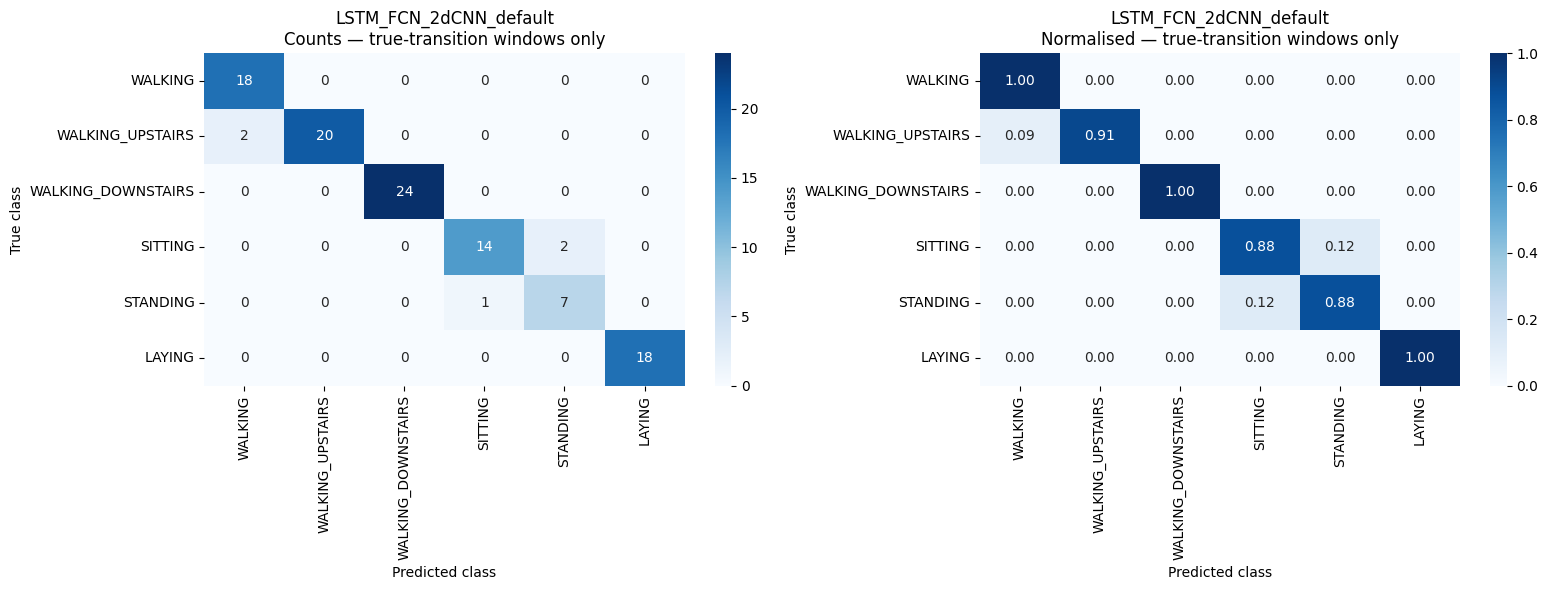


  LSTM_FCN_default__cwl__all_channels__lr_fixed
  Loaded checkpoint from models_medical/LSTM_FCN_default__cwl__all_channels__lr_fixed.pth

  Metrics:
    transition_recall    : 0.8919
    transition_precision : 0.6071
    transition_f1        : 0.7225
    f1_transition_only   : 0.9100
    f1_macro             : 0.7108
    median_error         : 0.0000
    max_class_error      : 6.0000


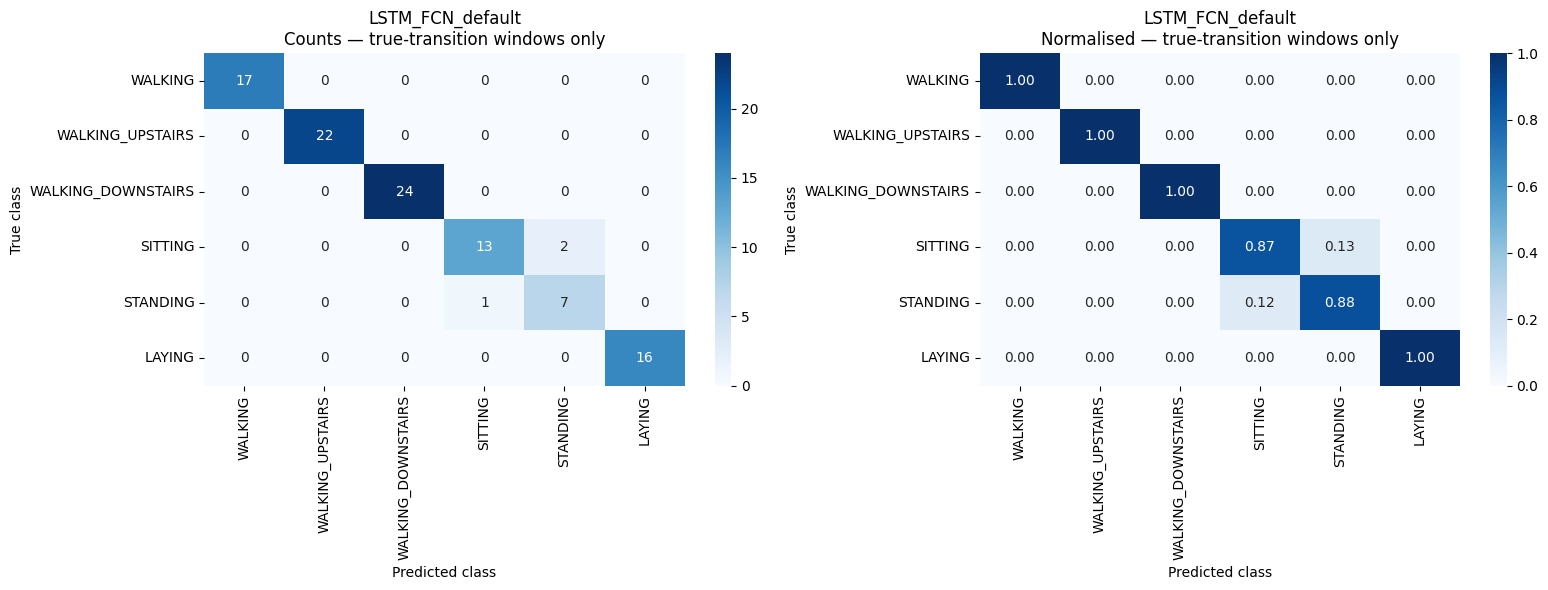


  XCM_LSTM_default__cwl__all_channels__lr_fixed
  Loaded checkpoint from models_medical/XCM_LSTM_default__cwl__all_channels__lr_fixed.pth

  Metrics:
    transition_recall    : 0.8378
    transition_precision : 0.6918
    transition_f1        : 0.7578
    f1_transition_only   : 0.8444
    f1_macro             : 0.7219
    median_error         : 0.0000
    max_class_error      : 6.0000


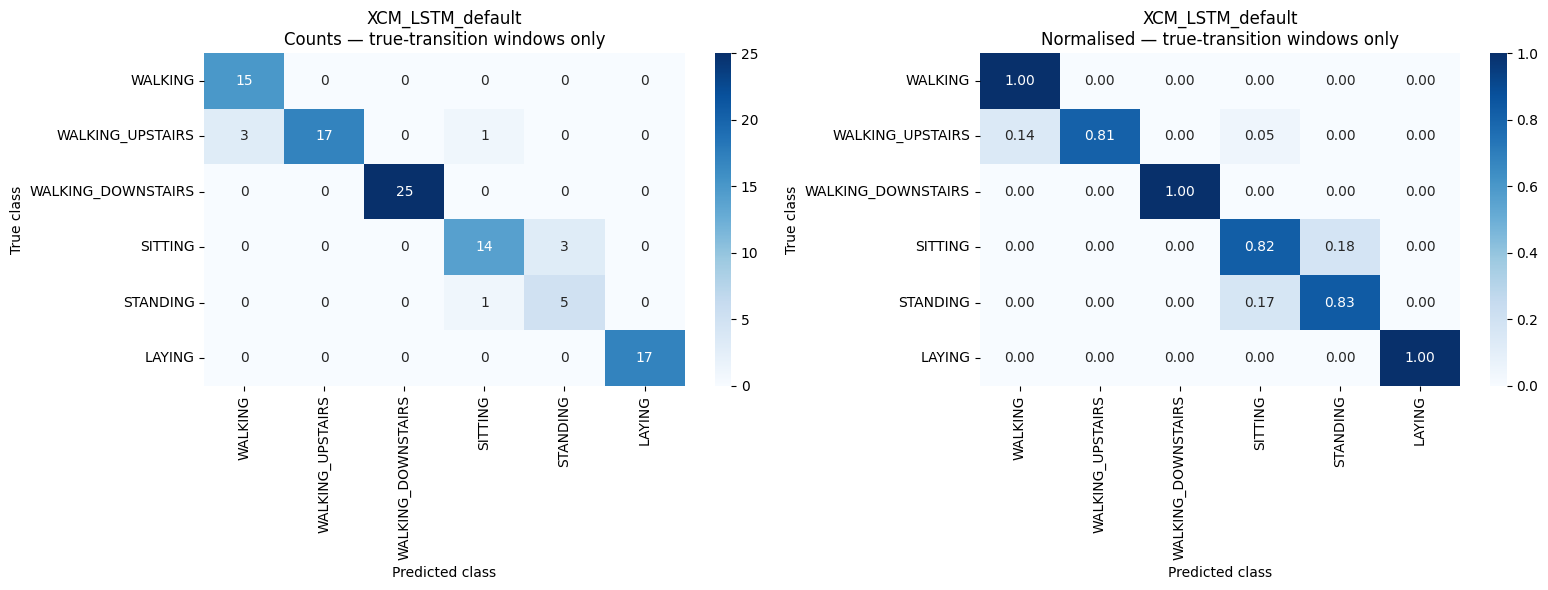

In [9]:
# ── Re-run best models from completed sweep ────────────────────────────────────
# Reads the CSV log automatically. Identifies top N runs by transition_recall
# (one per architecture). Mirrors North Sea exp-best-rerun cell.
TOP_N        = 3      # how many best models to re-run
RETRAIN      = False  # True = retrain from scratch; False = load saved checkpoint
BEST_N_EPOCHS = 50    # extended epoch budget when RETRAIN=True (vs 25 in sweep)

log_files = sorted(Path(".").glob("experiment_log_medical__shard*.csv"))
if not log_files:
    raise FileNotFoundError("No experiment_log_medical__shard*.csv found. Run the training loop first.")

log_df = pd.concat([pd.read_csv(p) for p in log_files], ignore_index=True)

top_runs = (
    log_df.sort_values('transition_recall', ascending=False)
          .drop_duplicates('arch_label')
          .head(TOP_N)
          .reset_index(drop=True)
)
print("Top runs selected for re-run:")
_dcols = [c for c in ['run_name', 'arch_label', 'loss_type', 'subset_name',
                       'transition_recall', 'f1_macro', 'median_error']
          if c in log_df.columns]
display(top_runs[_dcols])

ds_best = load_dataset()
R = COMMON_RECIPE

# Will hold last iteration's data for the standalone confusion cell below
_last_metrics     = None
_last_pred_labels = None
_last_arch        = None

for _, row in top_runs.iterrows():
    arch_label  = row['arch_label']
    loss_type   = row['loss_type']
    subset_name = row['subset_name']
    use_lr_find = bool(row.get('use_lr_find', False))
    run_name    = row['run_name']
    lr_tag      = "lr_find" if use_lr_find else "lr_fixed"

    print(f"\n{'='*60}")
    print(f"  {run_name}")
    print(f"{'='*60}")

    subset_idx_b, subset_names_b = resolve_subset(subset_name, ds_best["FEATURES_GEOX"])
    dls_b, _, _ = build_dataloader(ds_best, subset_idx_b, R["batch_size"])

    arch_class_b, arch_kwargs_b = ARCH_REGISTRY[arch_label]
    model_b  = build_model(arch_class_b, dls=dls_b, **arch_kwargs_b)
    device_b = next(model_b.parameters()).device

    wt_b = {
        "cwl":  compute_class_weights(ds_best["y_train"]),
        "ens":  compute_ens_weights(ds_best["y_train"]),
        "sqrt": compute_sqrt_weights(ds_best["y_train"]),
    }
    loss_b  = build_loss(loss_type, wt_b["cwl"], wt_b["ens"], wt_b["sqrt"], device_b)
    learn_b = Learner(dls_b, model_b, loss_func=loss_b, metrics=accuracy)

    if RETRAIN:
        lr_b = learn_b.lr_find(show_plot=False).valley if use_lr_find else R["fixed_lr"]
        cbs_b = [
            SaveModelCallback(monitor=R["monitor"]),
            EarlyStoppingCallback(monitor='valid_loss',
                                  min_delta=R["early_stop_min_delta"],
                                  patience=R["early_stop_patience"]),
        ]
        random_seed(0, use_cuda=True)
        t0 = time.time()
        learn_b.fit_one_cycle(BEST_N_EPOCHS, lr_b, cbs=cbs_b)
        print(f"  Trained {BEST_N_EPOCHS} epochs in {int(time.time()-t0)}s")
        ckpt = MODEL_DIR / f"best__{arch_label}__{loss_type}__{subset_name}.pth"
        torch.save(learn_b.model.state_dict(), ckpt)
        print(f"  Saved to {ckpt}")
    else:
        named_ckpt = MODEL_DIR / f"best__{arch_label}__{loss_type}__{subset_name}.pth"
        sweep_ckpt = MODEL_DIR / f"{run_name}.pth"
        load_path  = named_ckpt if named_ckpt.exists() else sweep_ckpt
        if not load_path.exists():
            raise FileNotFoundError(
                f"No checkpoint at {named_ckpt} or {sweep_ckpt}.\n"
                f"Set RETRAIN=True to train from scratch."
            )
        learn_b.model.load_state_dict(torch.load(load_path, map_location=device_b))
        learn_b.model.eval()
        print(f"  Loaded checkpoint from {load_path}")

    # ── Evaluate all 6 metrics ────────────────────────────────────────────────
    X_te_b   = ds_best["X_test"][:, subset_idx_b, :]
    metrics_b = evaluate_medical(learn_b, X_te_b, ds_best["y_test"], ds_best["PRED_COLUMN"])

    print(f"\n  Metrics:")
    print(f"    transition_recall    : {metrics_b['transition_recall']:.4f}")
    print(f"    transition_precision : {metrics_b['transition_precision']:.4f}")
    print(f"    transition_f1        : {metrics_b['transition_f1']:.4f}")
    print(f"    f1_transition_only   : {metrics_b['f1_transition_only']:.4f}")
    print(f"    f1_macro             : {metrics_b['f1_macro']:.4f}")
    print(f"    median_error         : {metrics_b['median_error']:.4f}")
    print(f"    max_class_error      : {metrics_b['max_class_error']:.4f}")

    # ── Confusion matrix — true-transition windows only (exclude None) ─────────
    pred_labels_trans = ds_best["PRED_COLUMN"][1:]   # ['WALKING', ...]
    all_preds_b = metrics_b["all_preds"]
    all_trues_b = metrics_b["all_trues"]
    true_trans_mask_b = all_trues_b > 0

    if true_trans_mask_b.sum() > 0:
        labels_idx  = list(range(1, len(ds_best["PRED_COLUMN"])))
        cm      = confusion_matrix(all_trues_b[true_trans_mask_b],
                                   all_preds_b[true_trans_mask_b], labels=labels_idx)
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        sns.heatmap(cm,      annot=True, fmt='d',    cmap='Blues',
                    xticklabels=pred_labels_trans, yticklabels=pred_labels_trans, ax=axes[0])
        axes[0].set_title(f"{arch_label}\nCounts — true-transition windows only")
        axes[0].set_ylabel("True class"); axes[0].set_xlabel("Predicted class")

        sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                    xticklabels=pred_labels_trans, yticklabels=pred_labels_trans, ax=axes[1])
        axes[1].set_title(f"{arch_label}\nNormalised — true-transition windows only")
        axes[1].set_ylabel("True class"); axes[1].set_xlabel("Predicted class")

        plt.tight_layout()
        plt.show()

    # Expose last run's data to the standalone confusion cell
    _last_metrics     = metrics_b
    _last_pred_labels = ds_best["PRED_COLUMN"]
    _last_arch        = arch_label

    # GPU cleanup
    learn_b.model.cpu()
    del learn_b, model_b, loss_b
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    _gc.collect()

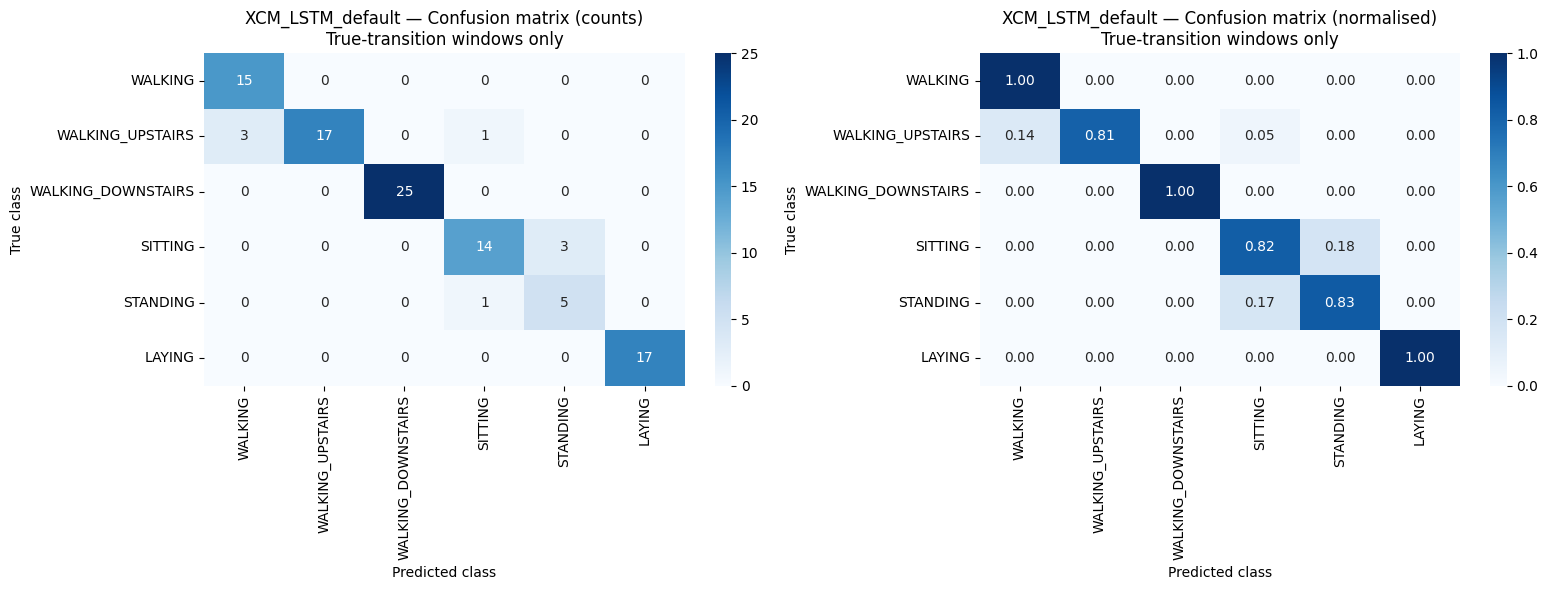

Per-class F1 (true-transition windows only):
  WALKING                   0.833
  WALKING_UPSTAIRS          0.850
  WALKING_DOWNSTAIRS        1.000
  SITTING                   0.824
  STANDING                  0.588
  LAYING                    0.971

  median_error    : 0.0000
  max_class_error : 6.0000


In [10]:
# ── Standalone confusion matrix (true-transition windows only) ─────────────────
# Uses _last_metrics set by the best-rerun cell above.
# Shows per-class F1 on true-transition windows only — None class excluded.

if '_last_metrics' not in dir() or _last_metrics is None:
    print("Run the best-model cell above first (_last_metrics not set).")
else:
    pred_labels_trans = _last_pred_labels[1:]   # exclude None
    all_preds_s = _last_metrics["all_preds"]
    all_trues_s = _last_metrics["all_trues"]
    true_trans_s = all_trues_s > 0

    if true_trans_s.sum() == 0:
        print("No true-transition windows found in test set.")
    else:
        labels_idx = list(range(1, len(_last_pred_labels)))
        cm      = confusion_matrix(all_trues_s[true_trans_s],
                                   all_preds_s[true_trans_s], labels=labels_idx)
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        sns.heatmap(cm,      annot=True, fmt='d',    cmap='Blues',
                    xticklabels=pred_labels_trans, yticklabels=pred_labels_trans, ax=axes[0])
        axes[0].set_title(f"{_last_arch} — Confusion matrix (counts)\nTrue-transition windows only")
        axes[0].set_ylabel("True class"); axes[0].set_xlabel("Predicted class")

        sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                    xticklabels=pred_labels_trans, yticklabels=pred_labels_trans, ax=axes[1])
        axes[1].set_title(f"{_last_arch} — Confusion matrix (normalised)\nTrue-transition windows only")
        axes[1].set_ylabel("True class"); axes[1].set_xlabel("Predicted class")

        plt.tight_layout()
        plt.show()

        per_cls_f1_trans = f1_score(
            all_trues_s[true_trans_s], all_preds_s[true_trans_s],
            labels=labels_idx, average=None, zero_division=0
        )
        print("Per-class F1 (true-transition windows only):")
        for lbl, f1_val in zip(pred_labels_trans, per_cls_f1_trans):
            print(f"  {lbl:<25} {f1_val:.3f}")
        print(f"\n  median_error    : {_last_metrics['median_error']:.4f}")
        print(f"  max_class_error : {_last_metrics['max_class_error']:.4f}")